# Quantum warm start for TVA plant scheduling
### QAOA finds a near-optimal day → classical repair makes it legal → the MILP solver starts from it and proves the perfect answer

**The idea in one sentence.** A quantum algorithm (QAOA) quickly proposes a schedule that is close to the best one, and we hand it to the standard classical solver (a MILP, the tool utilities use today) as its starting point. The solver then only has to close a small gap, and its final answer is always the proven optimum.

**Analogy.** A sudoku contest where you must *prove* your answer is best. If a friend hands you a nearly finished grid at the start, you skip every line of attack that can't beat it.

| Step | What happens | Section |
|---|---|---|
| 0 | The problem, the data, and the two classical baselines (exact MILP, cheapest-first rule) | 1–2 |
| — | What we tried before this, and why we moved on | 3 |
| 1 | Turn the whole day into one 20-qubit QUBO by grouping hours into 4 blocks | 4 |
| 2 | Run QAOA (simulator) and compare it with random guessing | 5 |
| 3 | Repair the best samples into a legal schedule: the **start state** | 6 |
| 4 | Give that start to HiGHS. Cold vs warm: when does the solver hold a good answer? | 7 |
| 5 | The same pipeline on quantum hardware / a noisy hardware simulator | 8 |
| — | All results on one page, and an honest verdict | 9–10 |

**How to run.** Kernel **qBraid-SDK (v0.12.2)** (needs `highspy`: `!python -m pip install highspy` once). Run top to bottom, about 2 minutes. The notebook uses two files from this folder: `quantum_warm_start_milp.py` (our pipeline) and `check.py` (the official checker). **Every "valid" and "rules broken" number comes from the official `check.check_schedule`.**

## 1. The problem and the data

Every day TVA decides which plants are **on** in each hour of tomorrow. The rules:

- output equals demand every hour, and every plant that is on makes between its minimum and maximum;
- the plants that are on could together make demand **+ reserve** (a safety margin);
- a plant that starts must stay on for its **minimum up time**, and one that stops must stay off for its **minimum down time**;
- at midnight only COAL is running.

Daily cost = startup costs + no-load costs (paid every hour a plant is on) + fuel/energy costs.

plant       min-max MW   $/MWh  no-load $/h  startup $  min up/down h  on at midnight
COAL        140-350      21.69          546     36,750       24 / 48    yes
GAS_CC      168-350      26.84          206     27,650        8 / 5     no
PEAKER_A     20-50       28.89          443      5,150        3 / 3     no
PEAKER_B     20-50       39.51          749      5,150        3 / 3     no
OIL          20-50      101.02          694        130        1 / 1     no

MILP size: 360 variables (240 on/off), 648 rules


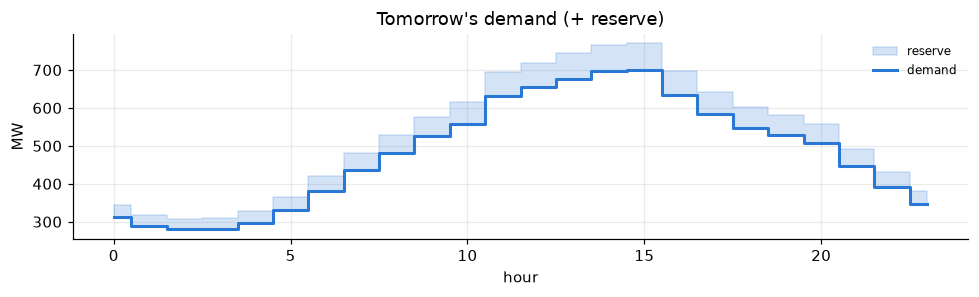

In [1]:
import os
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
import json, math, time, warnings
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from scipy.optimize import minimize
import highspy

import check                              # official checker
import quantum_warm_start_milp as qw      # our pipeline

SEED = 0
OUT = Path("warm_start_results"); OUT.mkdir(exist_ok=True)

# hardware switches (section 8). Results are cached in warm_start_results/hardware_runs.json.
RUN_NOISY_SIM = True                      # IonQ simulator + Forte-1 noise model: free
RUN_QPU       = False                     # IonQ Forte QPU: PAID, ~30 + 8 credits per shot
QPU_DEVICE    = "aws:ionq:qpu:forte-1"
MAX_CREDITS   = 0                         # the QPU cell refuses to submit above this estimate
HW_SHOTS      = 200
WAIT_S        = 900

COLORS = {"milp": "#2a78d6", "rule": "#eb6834", "warm": "#1baf7a", "random": "#eda100",
          "raw": "#e87ba4", "noisy": "#008300", "qpu": "#6250d6"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True})

plants = qw.load_plants("data/plants.csv")
demand, reserve = qw.load_demand("data/demand.csv")
T, n = len(demand), len(plants)
names = [p["plant_id"] for p in plants]
model = qw.Milp(plants, demand, reserve)

print(f"{'plant':<10}{'min-max MW':>12}{'$/MWh':>8}{'no-load $/h':>13}{'startup $':>11}{'min up/down h':>15}  on at midnight")
for p in plants:
    print(f"{p['plant_id']:<10}{p['pmin_mw']:>5.0f}-{p['pmax_mw']:<6.0f}{p['marginal_cost_per_mwh']:>8.2f}"
          f"{p['no_load_cost_per_h']:>13,.0f}{p['startup_cost']:>11,.0f}{p['min_up_h']:>9.0f} / {p['min_down_h']:<4.0f}"
          f"  {'yes' if p['on_at_start'] else 'no'}")
print(f"\nMILP size: {model.N} variables ({2 * n * T} on/off), {model.A.shape[0]} rules")

fig, ax = plt.subplots(figsize=(9, 2.8))
ax.fill_between(range(T), demand, demand + reserve, step="mid", color=COLORS["milp"], alpha=0.2, label="reserve")
ax.step(range(T), demand, where="mid", color=COLORS["milp"], lw=2, label="demand")
ax.set(xlabel="hour", ylabel="MW", title="Tomorrow's demand (+ reserve)")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

### Helpers

Thin wrappers around `quantum_warm_start_milp.py`. `run_highs` is the script's HiGHS call, but it also keeps the **timeline** of every better answer HiGHS finds. `train_qaoa` is exactly the angle-training step inside `qw.solve_qaoa`, split out so we keep the trained circuit and can count every shot on any backend.

In [2]:
def run_highs(model, start=None, time_limit=60.0, seed=0):
    h = highspy.Highs()
    h.setOptionValue("output_flag", False)
    h.setOptionValue("time_limit", float(time_limit))
    h.setOptionValue("random_seed", int(seed))
    h.setOptionValue("threads", 1)
    h.passModel(model.to_highs())
    timeline, t0 = [], [0.0]
    h.cbMipImprovingSolution.subscribe(
        lambda e: timeline.append((time.perf_counter() - t0[0], float(e.data_out.objective_function_value))))
    if start is not None:
        sol = highspy.HighsSolution()
        sol.col_value = list(map(float, start))
        sol.value_valid = True
        h.setSolution(sol)
    t0[0] = time.perf_counter()
    h.run()
    info = h.getInfo()
    return {"status": h.modelStatusToString(h.getModelStatus()), "seconds": time.perf_counter() - t0[0],
            "objective": info.objective_function_value, "nodes": int(info.mip_node_count),
            "pdi": info.primal_dual_integral, "timeline": timeline, "x": np.array(h.getSolution().col_value)}


def schedule_from_x(model, x):
    return np.round(x[:model.n * model.T]).reshape(model.n, model.T).T.astype(int)


def score(S, milp_cost, pl=None, dm=None, rs=None):
    return check.check_schedule(pl or plants, demand if dm is None else dm, reserve if rs is None else rs,
                                np.asarray(S), milp_cost=milp_cost, verbose=False)


def cheapest_first(plants, demand, reserve):
    """Starter TODO 1, as the README specifies: rank by marginal + no_load / pmax."""
    order = np.argsort([p["marginal_cost_per_mwh"] + p["no_load_cost_per_h"] / p["pmax_mw"] for p in plants])
    S = np.zeros((len(demand), len(plants)), int)
    for t in range(len(demand)):
        cap = 0.0
        for i in order:
            if cap >= demand[t] + reserve[t]:
                break
            S[t, i], cap = 1, cap + plants[i]["pmax_mw"]
    return S


def train_qaoa(qubo, p, alpha=0.25, maxiter=60):
    E = qubo.all_energies()
    shift, scale = E.mean(), E.std()
    Ehat = (E - shift) / scale
    order = np.argsort(E); E_sorted = Ehat[order]

    def cvar(probs):
        ps = probs[order]; cum = np.cumsum(ps); cut = np.searchsorted(cum, alpha)
        tot = ps[:cut] @ E_sorted[:cut] + (alpha - (cum[cut - 1] if cut else 0.0)) * E_sorted[min(cut, len(ps) - 1)]
        return tot / alpha

    obj = lambda th: cvar(np.abs(qw.qaoa_state(Ehat, th[:p], th[p:], qubo.N)) ** 2)
    x0 = np.r_[np.linspace(0.1, 0.8, p), np.linspace(0.8, 0.1, p)]
    t0 = time.perf_counter()
    res = minimize(obj, x0, method="COBYLA", options={"maxiter": maxiter, "rhobeg": 0.3})
    probs = np.abs(qw.qaoa_state(Ehat, res.x[:p], res.x[p:], qubo.N)) ** 2
    return {"E": E, "shift": shift, "scale": scale, "gammas": res.x[:p], "betas": res.x[p:],
            "cvar": res.fun, "cvar_uniform": cvar(np.full(2 ** qubo.N, 2.0 ** -qubo.N)),
            "probs": probs / probs.sum(), "nfev": res.nfev, "seconds": time.perf_counter() - t0}


def measured_circuit(qubo, tr):
    qc = qw.qaoa_circuit(qubo, tr["scale"], tr["shift"], tr["gammas"], tr["betas"])
    qc.measure_all()
    return qc


def sample_aer(qc, shots, seed=0):
    from qiskit import transpile
    from qiskit_aer import AerSimulator
    sim = AerSimulator(seed_simulator=seed)
    return {int(s.replace(" ", ""), 2): c for s, c in sim.run(transpile(qc, sim), shots=shots).result().get_counts().items()}


def sample_probs(probs, shots, seed=0):
    zs, cs = np.unique(np.random.default_rng(seed).choice(len(probs), size=shots, p=probs), return_counts=True)
    return dict(zip(zs.tolist(), cs.tolist()))


def sample_uniform(N, shots, seed=0):
    zs, cs = np.unique(np.random.default_rng(seed).integers(0, 2 ** N, shots), return_counts=True)
    return dict(zip(zs.tolist(), cs.tolist()))


def best_start(counts, qubo, model, E, candidates=50):
    """Repair the `candidates` lowest-energy samples, keep the cheapest legal one -> (schedule, cost)."""
    best_S, best_cost = None, math.inf
    for z in sorted(counts, key=lambda z: E[z])[:candidates]:
        S = qw.repair(model, qubo.to_schedule(qw.bits_of(z, qubo.N), model.T))
        if S is not None and (c := qw.true_cost(model, S)) < best_cost:
            best_S, best_cost = S, c
    return best_S, best_cost


def shot_stats(counts, qubo, model, E):
    """Share of shots: valid as sampled (official checker), valid after repair, hitting the QUBO optimum,
    landing in the cheapest 5% of all bitstrings."""
    shots = sum(counts.values()); raw = rep = 0
    for z, c in counts.items():
        S0 = qubo.to_schedule(qw.bits_of(z, qubo.N), model.T)
        raw += c * check.check_schedule(model.plants, model.demand, model.reserve, S0, verbose=False)["valid"]
        rep += c * (qw.repair(model, S0) is not None)
    q5 = np.quantile(E, 0.05)
    return {"shots": shots, "raw_valid": raw / shots, "repairable": rep / shots,
            "p_opt": sum(c for z, c in counts.items() if E[z] <= E.min() + 1e-9) / shots,
            "low5": sum(c for z, c in counts.items() if E[z] <= q5) / shots}


def plot_schedule(ax, S, r, title, color):
    ax.imshow(np.asarray(S).T, aspect="auto", cmap=ListedColormap(["#f0efec", color]), vmin=0, vmax=1,
              interpolation="none")
    ax.set_yticks(range(n + 1), names + ["(hour)"], fontsize=7)
    ax.set_xticks(range(0, T, 2)); ax.set_xticks(np.arange(-.5, T), minor=True)
    ax.set_yticks(np.arange(-.5, n + 1), minor=True)
    ax.grid(which="minor", color="white", lw=1.5); ax.grid(which="major", visible=False)
    ax.tick_params(which="minor", length=0); ax.set_ylim(n + 0.5, -0.5)
    for t, pid, rule, detail in r["violations"]:
        ax.plot(t, names.index(pid) if pid in names else n, "x", color="#d03b3b", ms=9, mew=2.5)
    status = "valid" if r["valid"] else f"{len(r['violations'])} rule(s) broken (red ✕)"
    ax.set_title(f"{title}: ${r['total_cost']:,.0f} ({r['gap_pct']:+.2f}%), {status}", fontsize=9, loc="left")

print("helpers ready")

helpers ready


## 2. The classical baselines

- **Exact MILP**: HiGHS solves the full model (360 variables) and proves the cheapest legal day. This is what a utility uses today.
- **Cheapest-first rule** (starter TODO 1): rank plants by cost per MWh at full output and switch them on down the list until capacity covers demand + reserve. It ignores startup costs and min up/down times.

> The `starter.ipynb` version of TODO 1 computes `(marginal + no_load) / pmax` instead of `marginal + no_load / pmax`. That ranks GAS_CC ahead of COAL and gives the often-quoted **+13.80%, 2 rules broken**. We use the README's formula here.

In [3]:
cold = run_highs(model, None, seed=SEED)
OPT = cold["objective"]
milp_S = schedule_from_x(model, cold["x"])
rule_S = cheapest_first(plants, demand, reserve)
milp_r, rule_r = score(milp_S, OPT), score(rule_S, OPT)

print(f"Exact MILP:          ${OPT:,.0f}/day  (proven optimal in {cold['seconds']:.3f} s), "
      f"{'valid' if milp_r['valid'] else 'NOT valid'}")
print(f"Cheapest-first rule: ${rule_r['total_cost']:,.0f}/day  ({rule_r['gap_pct']:+.2f}%), "
      f"{len(rule_r['violations'])} rule(s) broken")
for t, pid, rule, detail in rule_r["violations"]:
    print(f"    hour {t:>2}  {pid:<9} {rule}: {detail}")

Running HiGHS 1.16.0 (git hash: f3f113d): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
Exact MILP:          $327,924/day  (proven optimal in 0.034 s), valid
Cheapest-first rule: $330,594/day  (+0.81%), 1 rule(s) broken
    hour 16  PEAKER_B  min up broken: turned off after 2 h on (needs 3)


## 3. What we tried before this, and why we moved on

Full write-up: [`explanation/README.md`](./explanation/README.md). Numbers: `explanation/results/*.json`. Figures: `explanation/figures/`. Below are the 10-plant numbers (gap = cost above the MILP optimum).

| Attempt | What it is | 10-plant result | Why we moved on |
|---|---|---|---|
| Starter loop | one QUBO per hour, QAOA, keep valid samples | +7.06% on 5 plants; random guessing scores the same | the classical filter does the work |
| **Pure QAOA**, hour by hour | QAOA only, no classical help | **+48.1%, 28 rules broken** | the one-hour QUBO can't see min up/down times; plants flicker on and off |
| + rule checking | locks, validity filter, local search | +7.5%, 0 broken | the gap stays at 5–7% because each hour can't see the rest of the day |
| Hour grouping (blocks) | one QUBO for many hours | +0.85% after polish (K=3, 34 qubits) | good schedules need more qubits than QAOA can simulate (annealing stand-in) |
| Full-day QUBO | one QUBO for all 24 h | +0.24% (701 qubits, annealed) | far beyond any QPU or simulator |
| Lagrangian incentives (`hybrid_uc/`) | classical prices + hour-by-hour QAOA + repair | +0.00–0.34% | the classical stages alone already reach +0.00% |
| **Quantum warm start** (this notebook) | QAOA → repair → MILP start | **0.00%, proven optimal** | quantum helps the exact solver instead of replacing it |

**The lesson:** formulations small enough for QAOA give rough schedules, and formulations that give good schedules need hundreds of qubits. So we stopped asking QAOA to *replace* the MILP, and used it to give the MILP a head start.

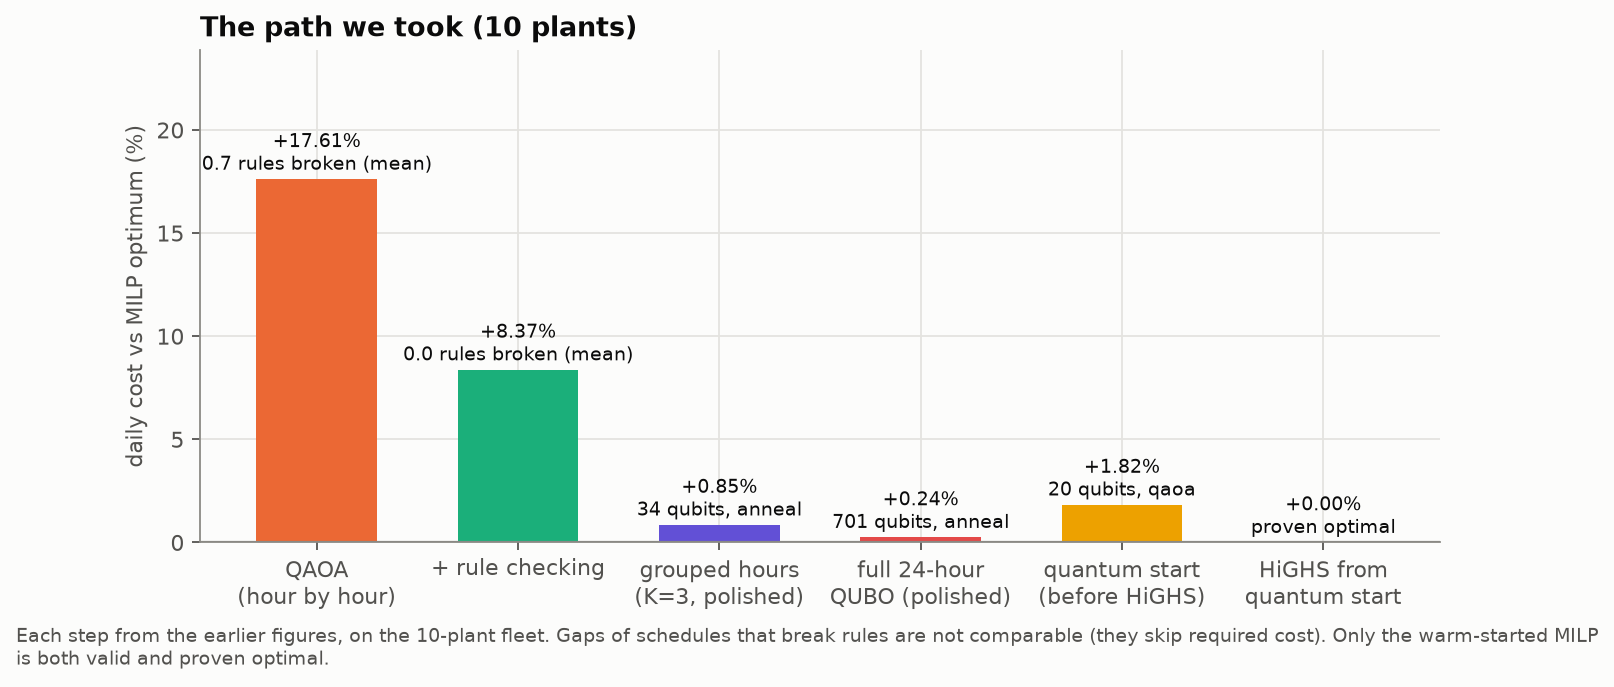

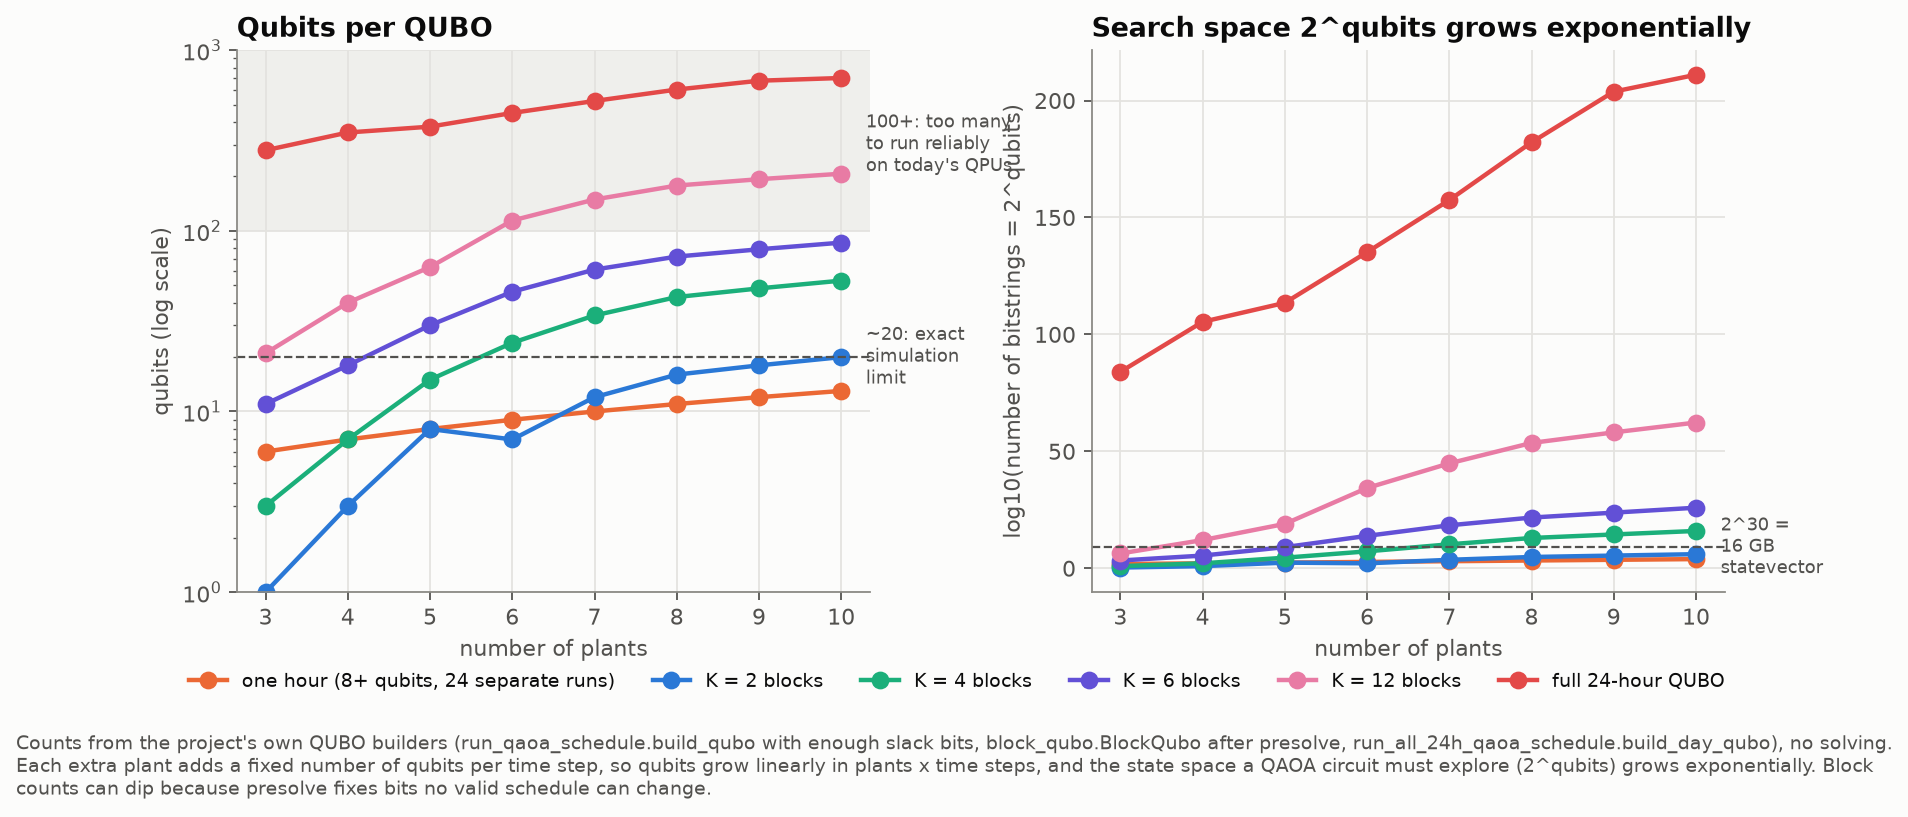

In [4]:
from IPython.display import Image, display
for f in ["explanation/figures/07_summary.png", "explanation/figures/04_qubit_growth.png"]:
    if Path(f).exists():
        display(Image(filename=f, width=850))
    else:
        print(f"(figure {f} not found: run explanation/make_figures.py)")

## 4. Step 1: the whole day as one 20-qubit QUBO

A QUBO with one qubit per plant per hour would need 5 × 24 = 120 qubits. So we cut the day into **K = 4 blocks** of hours with similar demand, and give each plant **one qubit per block**: "on for the whole block" or "off". That is 5 × 4 = **20 qubits**, small enough to simulate exactly.

The QUBO energy of a bitstring = estimated running cost + startup cost (a pair term between consecutive blocks) + a penalty if the block's capacity is far from what its worst hour needs. Min up/down times are **not** in the QUBO; the repair step handles them.

Blocks: ['0-6', '7-10', '11-17', '18-23'] -> 20 qubits, 1,048,576 possible bitstrings


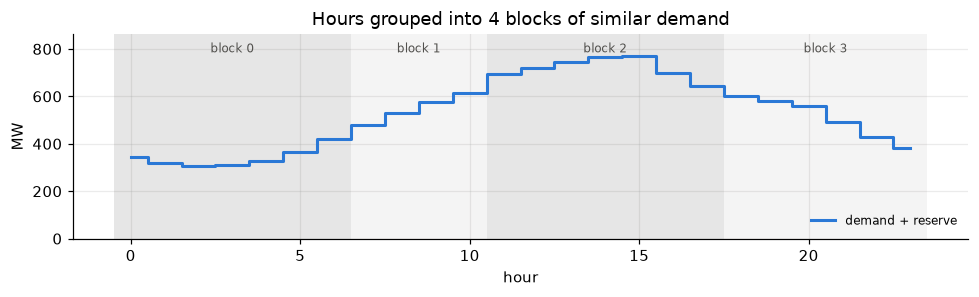

In [5]:
K = 4
blocks = qw.split_into_blocks(demand + reserve, K)
qubo = qw.Qubo(plants, demand, reserve, blocks)
E = qubo.all_energies()
print(f"Blocks: {[f'{h[0]}-{h[-1]}' for h in blocks]} -> {qubo.N} qubits, {2 ** qubo.N:,} possible bitstrings")

fig, ax = plt.subplots(figsize=(9, 2.8))
ax.step(range(T), demand + reserve, where="mid", color=COLORS["milp"], lw=2, label="demand + reserve")
for b, h in enumerate(blocks):
    ax.axvspan(h[0] - 0.5, h[-1] + 0.5, color="#52514e", alpha=0.06 if b % 2 else 0.14, lw=0)
    ax.text((h[0] + h[-1]) / 2, (demand + reserve).max() * 1.02, f"block {b}", ha="center", fontsize=8, color="#52514e")
ax.set(xlabel="hour", ylabel="MW", title="Hours grouped into 4 blocks of similar demand", ylim=(0, (demand + reserve).max() * 1.12))
ax.legend(frameon=False, fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

### An honest check of the QUBO: is its best answer a legal day?

We brute-force all 2²⁰ bitstrings, so this is the best answer any QAOA could ever find. It is **not legal**. In blocks 0 and 2 the QUBO prefers to leave capacity short, because the soft penalty costs less than switching on a peaker. That is why the next steps need a repair, and why we don't use QAOA's answer directly.

In [6]:
z_opt = int(np.argmin(E))
S_qubo_opt = qubo.to_schedule(qw.bits_of(z_opt, qubo.N), T)
r_qubo_opt = score(S_qubo_opt, OPT)
print(f"QUBO's own optimum: ${r_qubo_opt['total_cost']:,.0f} ({r_qubo_opt['gap_pct']:+.2f}%), "
      f"{len(r_qubo_opt['violations'])} rule(s) broken -> cheaper than the optimum only because it is illegal")
x = qw.bits_of(z_opt, qubo.N)
for b, h in enumerate(blocks):
    cap = sum(plants[i]["pmax_mw"] for i in range(n) if x[i * K + b])
    need = max(demand[t] + reserve[t] for t in h)
    print(f"  block {b} (hours {h[0]:>2}-{h[-1]:<2}): on = {'+'.join(names[i] for i in range(n) if x[i * K + b]):<14} "
          f"capacity {cap:.0f} MW vs needed {need:.0f} MW {'OK' if cap >= need else 'SHORT'}")
valid_low = sum(score(qubo.to_schedule(qw.bits_of(int(z), qubo.N), T), OPT)["valid"] for z in np.argsort(E)[:200])
print(f"Legal days among the 200 lowest-energy bitstrings: {valid_low}")

QUBO's own optimum: $313,517 (-4.39%), 7 rule(s) broken -> cheaper than the optimum only because it is illegal
  block 0 (hours  0-6 ): on = COAL           capacity 350 MW vs needed 420 MW SHORT
  block 1 (hours  7-10): on = COAL+GAS_CC    capacity 700 MW vs needed 615 MW OK
  block 2 (hours 11-17): on = COAL+GAS_CC    capacity 700 MW vs needed 770 MW SHORT
  block 3 (hours 18-23): on = COAL+GAS_CC    capacity 700 MW vs needed 602 MW OK
Legal days among the 200 lowest-energy bitstrings: 4


## 5. Step 2: QAOA on the simulator

QAOA prepares a quantum state in which cheap (low-energy) bitstrings are more likely to be measured. It has 2 layers here, with 4 angles tuned by a classical optimizer (COBYLA) on an exact simulation. Then we measure the circuit 4,000 times on Qiskit Aer.

**The control is random guessing**: 4,000 uniformly random bitstrings. If QAOA's shots aren't cheaper than random ones, QAOA isn't doing anything.

QAOA p=2, 20 qubits: trained in 8.1 s; circuit depth 27
CVaR(25%) energy: QAOA -2.40 vs random -1.24  (standardised, lower = cheaper)

4,000 shots                                 QAOA    random
land in the cheapest 5% of bitstrings     69.15%     5.78%
hit the QUBO optimum                       0.03%     0.00%
legal day as sampled                       2.40%     0.12%
legal day after repair                   100.00%   100.00%


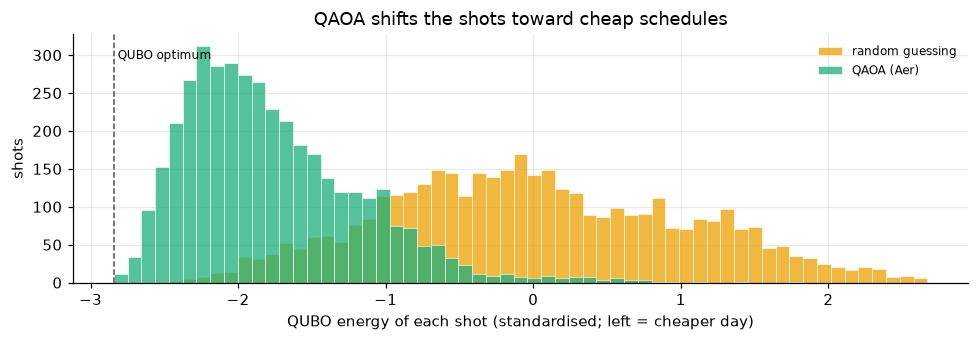

In [7]:
tr = train_qaoa(qubo, p=2)
qc = measured_circuit(qubo, tr)
t0 = time.perf_counter()
qaoa_counts = sample_aer(qc, 4000, SEED)
QUANTUM_S = tr["seconds"] + (time.perf_counter() - t0)
rand_counts = sample_uniform(qubo.N, 4000, SEED)
qs, rs_ = shot_stats(qaoa_counts, qubo, model, E), shot_stats(rand_counts, qubo, model, E)

print(f"QAOA p=2, {qubo.N} qubits: trained in {tr['seconds']:.1f} s; circuit depth {qc.depth()}")
print(f"CVaR(25%) energy: QAOA {tr['cvar']:+.2f} vs random {tr['cvar_uniform']:+.2f}  (standardised, lower = cheaper)\n")
print(f"{'4,000 shots':<38}{'QAOA':>10}{'random':>10}")
for k, label in [("low5", "land in the cheapest 5% of bitstrings"), ("p_opt", "hit the QUBO optimum"),
                 ("raw_valid", "legal day as sampled"), ("repairable", "legal day after repair")]:
    print(f"{label:<38}{qs[k]:>10.2%}{rs_[k]:>10.2%}")

Ehat = (E - E.mean()) / E.std()
fig, ax = plt.subplots(figsize=(9, 3.2))
bins = np.linspace(Ehat.min(), np.quantile(Ehat, 0.999), 60)
for cnt, label, color in [(rand_counts, "random guessing", COLORS["random"]), (qaoa_counts, "QAOA (Aer)", COLORS["warm"])]:
    ax.hist(np.repeat([Ehat[z] for z in cnt], list(cnt.values())), bins=bins, color=color, alpha=0.75,
            label=label, edgecolor="white", linewidth=0.5)
ax.axvline(Ehat.min(), color="#52514e", ls="--", lw=1); ax.text(Ehat.min(), ax.get_ylim()[1] * 0.9, " QUBO optimum", fontsize=8)
ax.set(xlabel="QUBO energy of each shot (standardised; left = cheaper day)", ylabel="shots",
       title="QAOA shifts the shots toward cheap schedules")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

## 6. Step 3: repair → the start state for the MILP

We take the 50 cheapest QAOA samples and **repair** each one with simple local rules (switch on the cheapest off plant where capacity is short, extend a run to its minimum up time, and so on). Then we keep the cheapest legal result. That schedule, plus the cheapest output split for each hour, is a complete MILP solution: our **start state**.

Repair took 0.03 s for 50 samples.
Best raw QAOA sample:   $313,517 (-4.39%), 7 rule(s) broken
Start state for HiGHS:  $331,596 (+1.12%), legal (0 rules broken)


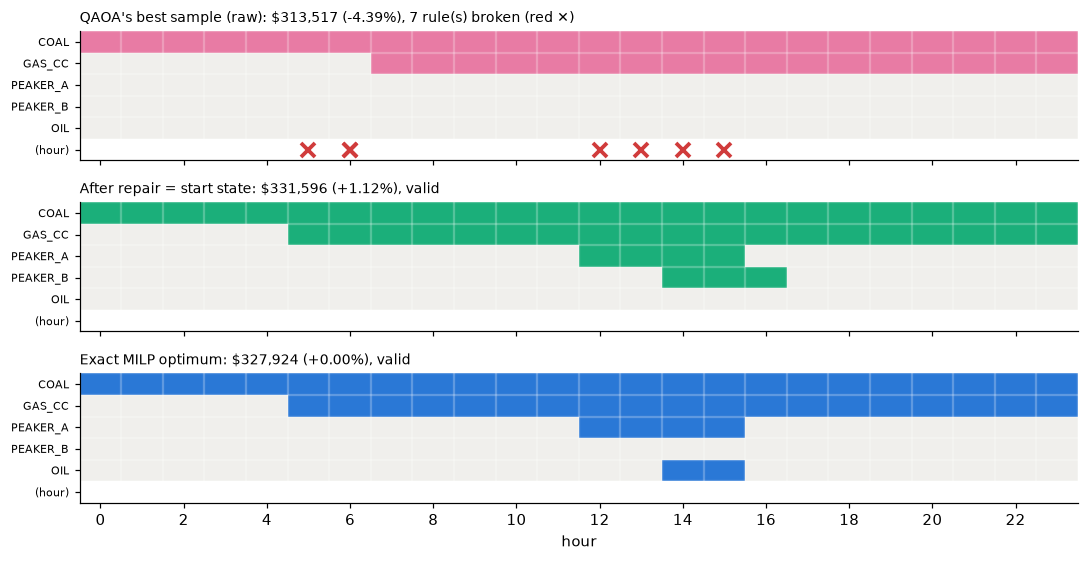

In [8]:
t0 = time.perf_counter()
start_S, start_cost = best_start(qaoa_counts, qubo, model, E)
REPAIR_S = time.perf_counter() - t0
start_x = qw.full_solution(model, start_S)
raw_S = qubo.to_schedule(qw.bits_of(min(qaoa_counts, key=lambda z: E[z]), qubo.N), T)
raw_r, start_r = score(raw_S, OPT), score(start_S, OPT)
assert start_r["valid"] and not model.violations(start_x)

print(f"Repair took {REPAIR_S:.2f} s for 50 samples.")
print(f"Best raw QAOA sample:   ${raw_r['total_cost']:,.0f} ({raw_r['gap_pct']:+.2f}%), {len(raw_r['violations'])} rule(s) broken")
print(f"Start state for HiGHS:  ${start_cost:,.0f} ({start_r['gap_pct']:+.2f}%), legal (0 rules broken)")

fig, axes = plt.subplots(3, 1, figsize=(10, 5.2), sharex=True)
plot_schedule(axes[0], raw_S, raw_r, "QAOA's best sample (raw)", COLORS["raw"])
plot_schedule(axes[1], start_S, start_r, "After repair = start state", COLORS["warm"])
plot_schedule(axes[2], milp_S, milp_r, "Exact MILP optimum", COLORS["milp"])
axes[-1].set_xlabel("hour")
plt.tight_layout(); plt.show()

## 7. Step 4: the MILP finishes the job, cold vs warm

Same solver (HiGHS), same model, 1 thread, 5 seeds. **Cold** = basic MILP, starting from nothing. **Warm** = given our start state.

What to look at:
- **When does the solver first hold a good answer?** Warm: at 0 s, a legal day about 1% from optimal. Cold: only after its own search.
- **Primal-dual integral**: the area under the "how far from proven optimal" curve over time. Lower means good answers came earlier.
- **Final answer**: identical. The warm start can't make the answer wrong; HiGHS still proves optimality.

We repeat on bigger fleets (copies of the 5 plants with costs jittered ±8%). For 20 and 40 plants the QUBO is too big to simulate QAOA (80 / 160 qubits), so **simulated annealing** stands in for the quantum step there, labeled as such.

In [9]:
REPEATS = 5

def within(run, opt, pct, start_cost=None):
    """Seconds until HiGHS holds a schedule within pct% of the optimum (0 if the start already is)."""
    if start_cost is not None and start_cost <= opt * (1 + pct / 100):
        return 0.0
    return next((t for t, c in run["timeline"] if c <= opt * (1 + pct / 100)), run["seconds"])


def compare(m, start_x, start_cost):
    cold_runs = [run_highs(m, None, seed=SEED + r) for r in range(REPEATS)]
    warm_runs = [run_highs(m, start_x, seed=SEED + r) for r in range(REPEATS)]
    opt = min(r["objective"] for r in cold_runs + warm_runs)
    med = lambda rs, f: float(np.median([f(r) for r in rs]))
    row = {}
    for mode, rs, sc in [("cold", cold_runs, None), ("warm", warm_runs, start_cost)]:
        row[mode] = {"seconds": med(rs, lambda r: r["seconds"]), "nodes": med(rs, lambda r: r["nodes"]),
                     "pdi": med(rs, lambda r: r["pdi"]), "t_2.5": med(rs, lambda r: within(r, opt, 2.5, sc)),
                     "first": med(rs, lambda r: r["timeline"][0][0] if r["timeline"] else r["seconds"]) if sc is None else 0.0,
                     "first_gap": (100 * (rs[0]["timeline"][0][1] - opt) / opt if rs[0]["timeline"] else math.nan)
                                  if sc is None else 100 * (sc - opt) / opt,
                     "objective": min(r["objective"] for r in rs), "status": rs[0]["status"], "run0": rs[0]}
    return opt, row


fleet_rows = [("5 plants", "QAOA, 20 qubits", model, start_x, start_cost, QUANTUM_S + REPAIR_S)]
for copies in (4, 8):
    pc, dc, rc = qw.bigger_fleet(plants, demand, reserve, copies, SEED)
    m = qw.Milp(pc, dc, rc)
    qb = qw.Qubo(pc, dc, rc, qw.split_into_blocks(dc + rc, 4))
    t0 = time.perf_counter()
    cands, _ = qw.solve_anneal(qb, seed=SEED, log=lambda *a: None)
    S_best, c_best = None, math.inf
    for xx in cands[:50]:
        S = qw.repair(m, qb.to_schedule(xx, m.T))
        if S is not None and (c := qw.true_cost(m, S)) < c_best:
            S_best, c_best = S, c
    fleet_rows.append((f"{len(pc)} plants", f"annealing, {qb.N} bits", m, qw.full_solution(m, S_best), c_best,
                       time.perf_counter() - t0))

results7 = []
print(f"{'fleet':<10}{'quantum step':<22}{'mode':<6}{'start':>8}{'1st answer':>12}{'≤2.5% at':>10}"
      f"{'proven opt.':>13}{'nodes':>7}{'P-D integral':>14}   final cost")
for label, solver, m, sx, sc, q_s in fleet_rows:
    opt, row = compare(m, sx, sc)
    results7.append((label, solver, opt, row, sc, q_s))
    for mode in ("cold", "warm"):
        r = row[mode]
        print(f"{label:<10}{solver if mode == 'cold' else '':<22}{mode:<6}"
              f"{(f'{100 * (sc - opt) / opt:+.2f}%' if mode == 'warm' else '-'):>8}"
              f"{r['first'] * 1000:>9.0f} ms{r['t_2.5'] * 1000:>7.0f} ms{r['seconds'] * 1000:>10.0f} ms"
              f"{r['nodes']:>7.0f}{r['pdi']:>14.4f}   ${r['objective']:,.0f} {r['status']}")
    print(f"{'':<10}{'':<22}quantum + repair step took {q_s:.1f} s (simulated; not QPU time)\n")

fleet     quantum step          mode     start  1st answer  ≤2.5% at  proven opt.  nodes  P-D integral   final cost


5 plants  QAOA, 20 qubits       cold         -       14 ms     15 ms        34 ms      1        0.0142   $327,924 Optimal
5 plants                        warm    +1.12%        0 ms      0 ms        31 ms      1        0.0126   $327,924 Optimal
                                quantum + repair step took 8.4 s (simulated; not QPU time)



20 plants annealing, 80 bits    cold         -       66 ms     66 ms       121 ms      1        0.0664   $1,272,970 Optimal
20 plants                       warm    +1.78%        0 ms      0 ms       116 ms      1        0.0401   $1,272,970 Optimal
                                quantum + repair step took 0.8 s (simulated; not QPU time)



40 plants annealing, 160 bits   cold         -      247 ms    247 ms       514 ms      1        0.2513   $2,556,240 Optimal
40 plants                       warm    +2.19%        0 ms      0 ms       514 ms      1        0.2377   $2,556,240 Optimal
                                quantum + repair step took 1.7 s (simulated; not QPU time)



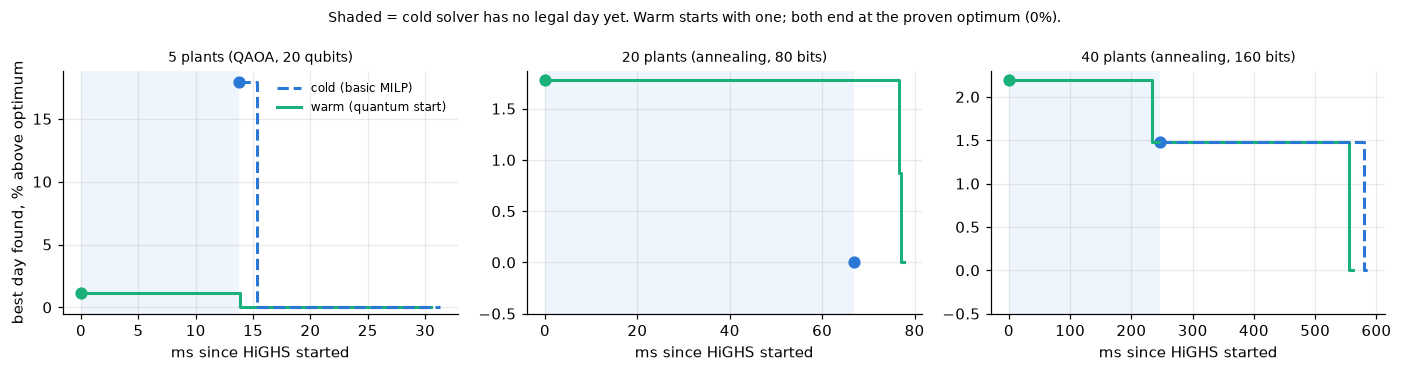

In [10]:
fig, axes = plt.subplots(1, len(results7), figsize=(13, 3.4), sharey=False)
for ax, (label, solver, opt, row, sc, q_s) in zip(axes, results7):
    for mode, color in [("cold", COLORS["milp"]), ("warm", COLORS["warm"])]:
        r = row[mode]["run0"]
        pts = ([(0.0, sc)] if mode == "warm" else []) + list(r["timeline"])
        if not pts:
            continue
        ts = [p[0] * 1000 for p in pts] + [r["seconds"] * 1000]
        gs = [100 * (p[1] - opt) / opt for p in pts]; gs.append(gs[-1])
        ax.step(ts, gs, where="post", color=color, lw=2, ls="--" if mode == "cold" else "-",
                label="cold (basic MILP)" if mode == "cold" else "warm (quantum start)", zorder=3 if mode == "cold" else 2)
        ax.plot(ts[0], gs[0], "o", color=color, ms=7)
        if mode == "cold":
            ax.axvspan(0, ts[0], color=COLORS["milp"], alpha=0.07, lw=0)
    ax.set(title=f"{label} ({solver})", xlabel="ms since HiGHS started")
    ax.title.set_fontsize(9)
    ax.set_ylim(bottom=-0.5)
axes[0].set_ylabel("best day found, % above optimum")
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Shaded = cold solver has no legal day yet. Warm starts with one; both end at the proven optimum (0%).", fontsize=9)
plt.tight_layout(); plt.show()

## 8. Step 5: hardware next to the simulator

Hardware needs short circuits, so for device runs we use the smallest version of the same QUBO: **2 blocks → 10 qubits, 1 QAOA layer, 50 two-qubit (CX) gates**. Angles are trained on the simulator, and then the *same* circuit is measured with 200 shots on:

- **Aer**: noiseless simulator on this Lab instance;
- **IonQ simulator with the Forte-1 noise model** (`ionq:ionq:sim:simulator`): free, models the real machine's noise;
- **IonQ Forte QPU** (`RUN_QPU`): paid. It refuses to submit above `MAX_CREDITS`;
- **random guessing**: the no-quantum control.

Each set of shots goes through the same repair → start state → HiGHS steps. Job results are cached in `warm_start_results/hardware_runs.json`, so re-running never resubmits a finished job.

Hardware circuit: 10 qubits, 50 CX gates, depth 31


IonQ sim + Forte-1 noise: using cached result of job ionq:ionq:sim:simulator-842a-qjob-6af901e4c8f5265fb3f21de4

backend                      cheapest 5% QUBO opt. legal raw after repair    start   HiGHS final  job
Aer (noiseless simulator)          34.0%      1.0%      0.0%       100.0%   +1.12%  $    327,924  local


IonQ sim + Forte-1 noise           22.0%      1.0%      0.0%       100.0%   +1.12%  $    327,924  ionq:ionq:sim:simulator-842a-qjob-6af901e4c8f5265fb3f21de4 (COMPLETED, 16 s incl. queue)


random guessing                     4.0%      0.0%      0.0%       100.0%   +1.12%  $    327,924  local


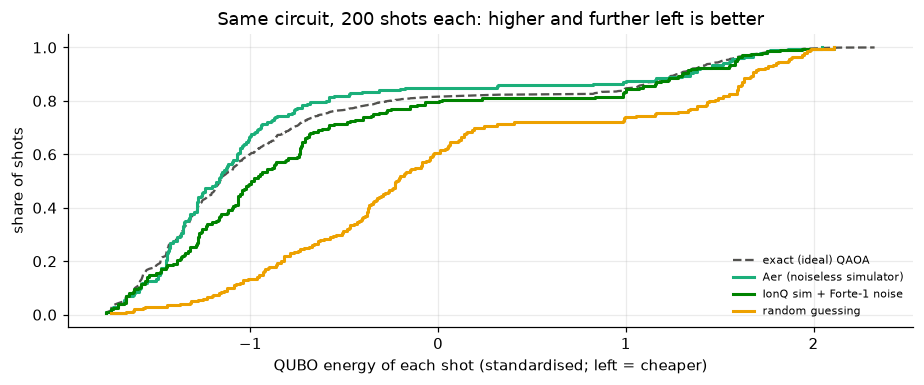

In [11]:
from qiskit import transpile

blocks_hw = qw.split_into_blocks(demand + reserve, 2)
qubo_hw = qw.Qubo(plants, demand, reserve, blocks_hw)
tr_hw = train_qaoa(qubo_hw, p=1)
qc_hw = transpile(measured_circuit(qubo_hw, tr_hw), basis_gates=["h", "rx", "rz", "cx"], optimization_level=1)
CX = qc_hw.count_ops().get("cx", 0)
print(f"Hardware circuit: {qubo_hw.N} qubits, {CX} CX gates, depth {qc_hw.depth()}")

CACHE = OUT / "hardware_runs.json"
cache = json.loads(CACHE.read_text()) if CACHE.exists() else {}


def device_counts(label, device_id, runtime_options=None):
    from qbraid.runtime import QbraidProvider, QbraidJob
    rec = cache.get(label)
    if rec and rec.get("counts"):
        print(f"{label}: using cached result of job {rec['job_id']}")
        return {int(k): v for k, v in rec["counts"].items()}
    if rec and rec.get("job_id") and rec.get("status") not in ("FAILED", "CANCELLED"):
        job = QbraidJob(rec["job_id"]); print(f"{label}: checking earlier job {rec['job_id']}")
    else:
        dev = QbraidProvider().get_device(device_id)
        if "ONLINE" not in str(dev.status()):
            print(f"{label}: {device_id} is {dev.status()}, skipped"); return None
        pr = dev.profile.pricing
        est = (float(pr.perTask) + float(pr.perShot) * HW_SHOTS) if pr else 0.0
        per_min = float(pr.perMinute) if pr else 0.0
        print(f"{label}: {device_id}, estimated {est:,.0f} credits (${est / 100:,.2f})")
        if est > MAX_CREDITS or per_min > 0:
            print(f"   NOT submitted: above MAX_CREDITS = {MAX_CREDITS}"); return None
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            job = dev.run(qc_hw, shots=HW_SHOTS, **({"runtime_options": runtime_options} if runtime_options else {}))
        rec = cache[label] = {"device": device_id, "job_id": job.id, "shots": HW_SHOTS, "est_credits": est,
                              "runtime_options": runtime_options, "submitted": time.time(), "cx": CX,
                              "depth": qc_hw.depth()}
        CACHE.write_text(json.dumps(cache, indent=1)); print(f"   submitted job {job.id}")
    try:
        job.wait_for_final_state(timeout=WAIT_S)
    except Exception:
        rec["status"] = str(job.status()).split(".")[-1]; CACHE.write_text(json.dumps(cache, indent=1))
        print(f"   still {rec['status']} after {WAIT_S} s; re-run this cell later"); return None
    rec["status"] = str(job.status()).split(".")[-1]
    if rec["status"] != "COMPLETED":
        CACHE.write_text(json.dumps(cache, indent=1)); print(f"   job ended {rec['status']}"); return None
    counts = {int(b.replace(" ", ""), 2): int(c) for b, c in job.result().data.get_counts().items()}
    rec.update(counts={str(k): v for k, v in counts.items()}, finished=time.time())
    rec["wall_s"] = rec["finished"] - rec["submitted"]
    CACHE.write_text(json.dumps(cache, indent=1))
    return counts


backends = {"Aer (noiseless simulator)": sample_aer(qc_hw, HW_SHOTS, SEED)}
if RUN_NOISY_SIM:
    backends["IonQ sim + Forte-1 noise"] = device_counts("IonQ sim + Forte-1 noise", "ionq:ionq:sim:simulator",
                                                         {"noise_model": "forte-1"})
if RUN_QPU or cache.get("IonQ Forte QPU", {}).get("job_id"):
    backends["IonQ Forte QPU"] = device_counts("IonQ Forte QPU", QPU_DEVICE)
backends["random guessing"] = sample_uniform(qubo_hw.N, HW_SHOTS, SEED)
backends = {k: v for k, v in backends.items() if v}

E_hw = tr_hw["E"]
hw = {}
print(f"\n{'backend':<28}{'cheapest 5%':>12}{'QUBO opt.':>10}{'legal raw':>10}{'after repair':>13}{'start':>9}{'HiGHS final':>14}  job")
for label, cnt in backends.items():
    st = shot_stats(cnt, qubo_hw, model, E_hw)
    S, c = best_start(cnt, qubo_hw, model, E_hw)
    fin = run_highs(model, qw.full_solution(model, S), seed=SEED)
    hw[label] = {**st, "start_gap": 100 * (c - OPT) / OPT, "final": fin["objective"]}
    rec = cache.get(label, {})
    print(f"{label:<28}{st['low5']:>12.1%}{st['p_opt']:>10.1%}{st['raw_valid']:>10.1%}{st['repairable']:>13.1%}"
          f"{hw[label]['start_gap']:>+8.2f}%  ${fin['objective']:>11,.0f}  "
          + (f"{rec['job_id']} ({rec.get('status')}, {rec.get('wall_s', 0):.0f} s incl. queue)" if rec else "local"))

HW_COLORS = {"Aer (noiseless simulator)": COLORS["warm"], "IonQ sim + Forte-1 noise": COLORS["noisy"],
             "IonQ Forte QPU": COLORS["qpu"], "random guessing": COLORS["random"]}
Eh = (E_hw - E_hw.mean()) / E_hw.std(); order = np.argsort(Eh)
fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.plot(Eh[order], np.cumsum(tr_hw["probs"][order]), color="#52514e", ls="--", lw=1.5, label="exact (ideal) QAOA")
for label, cnt in backends.items():
    e = np.sort(np.repeat([Eh[z] for z in cnt], list(cnt.values())))
    ax.step(e, np.arange(1, len(e) + 1) / len(e), where="post", color=HW_COLORS[label], lw=2, label=label)
ax.set(xlabel="QUBO energy of each shot (standardised; left = cheaper)", ylabel="share of shots",
       title=f"Same circuit, {HW_SHOTS} shots each: higher and further left is better")
ax.legend(fontsize=7, frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

## 9. All results on one page

The answers to the judges' checklist, from this run.

In [12]:
r5 = results7[0][3]
print("DAILY COST, 5 plants x 24 h (every rule checked by check.check_schedule)")
print(f"{'method':<38}{'daily cost':>12}{'vs MILP':>10}{'rules broken':>14}")
final_r = score(schedule_from_x(model, r5["warm"]["run0"]["x"]), OPT)
for label, r in [("Exact MILP (basic, cold)", milp_r), ("Cheapest-first rule", rule_r),
                 ("QAOA best raw sample", raw_r), ("QAOA + repair (start state)", start_r),
                 ("Warm-started MILP (our final answer)", final_r)]:
    print(f"{label:<38}${r['total_cost']:>11,.0f}{r['gap_pct']:>+9.2f}%{len(r['violations']):>14}")

print("\nHOW OFTEN ANSWERS WERE VALID (4,000 shots, 20 qubits)")
print(f"  legal as sampled:   QAOA {qs['raw_valid']:.1%}   random {rs_['raw_valid']:.1%}")
print(f"  legal after repair: QAOA {qs['repairable']:.1%}   random {rs_['repairable']:.1%}")
print(f"  cheapest 5% of all bitstrings: QAOA {qs['low5']:.1%}   random {rs_['low5']:.1%}")

print("\nMILP: COLD vs WARM (median of 5 seeds)")
for label, solver, opt, row, sc, q_s in results7:
    c, w = row["cold"], row["warm"]
    print(f"  {label:<10} first legal day: cold {c['first'] * 1000:.0f} ms ({c['first_gap']:+.1f}%) vs warm 0 ms "
          f"({w['first_gap']:+.2f}%); proven optimal: {c['seconds'] * 1000:.0f} -> {w['seconds'] * 1000:.0f} ms; "
          f"P-D integral {c['pdi']:.4f} -> {w['pdi']:.4f} ({100 * (w['pdi'] - c['pdi']) / c['pdi']:+.0f}%)")

print("\nHARDWARE vs SIMULATOR (10 qubits, 50 CX, 200 shots)")
for label, h in hw.items():
    print(f"  {label:<28} cheapest-5% share {h['low5']:.0%}, start {h['start_gap']:+.2f}%, final ${h['final']:,.0f}")
if "IonQ Forte QPU" not in hw:
    print("  IonQ Forte QPU: not run yet (RUN_QPU = False)")

print(f"\nTIME: quantum step {QUANTUM_S:.1f} s (simulated) + repair {REPAIR_S:.2f} s; "
      f"cold MILP alone {r5['cold']['seconds']:.3f} s")

DAILY COST, 5 plants x 24 h (every rule checked by check.check_schedule)
method                                  daily cost   vs MILP  rules broken
Exact MILP (basic, cold)              $    327,924    +0.00%             0
Cheapest-first rule                   $    330,594    +0.81%             1
QAOA best raw sample                  $    313,517    -4.39%             7
QAOA + repair (start state)           $    331,596    +1.12%             0
Warm-started MILP (our final answer)  $    327,924    +0.00%             0

HOW OFTEN ANSWERS WERE VALID (4,000 shots, 20 qubits)
  legal as sampled:   QAOA 2.4%   random 0.1%
  legal after repair: QAOA 100.0%   random 100.0%
  cheapest 5% of all bitstrings: QAOA 69.2%   random 5.8%

MILP: COLD vs WARM (median of 5 seeds)
  5 plants   first legal day: cold 14 ms (+17.9%) vs warm 0 ms (+1.12%); proven optimal: 34 -> 31 ms; P-D integral 0.0142 -> 0.0126 (-11%)
  20 plants  first legal day: cold 66 ms (+0.0%) vs warm 0 ms (+1.78%); proven optimal: 1

## 10. Honest verdict

**What works**
- The pipeline works end to end: QAOA → repair → start state → HiGHS. The final answer is the **proven optimum, $327,924/day, with 0 rules broken**. Our start state is a legal day 1.12% above optimal. That beats the starter's hour-by-hour QAOA (+7.06%) and the starter's cheapest-first code (+13.80%). The correctly ranked cheapest-first rule is cheaper (+0.81%), but it breaks a min-up rule.
- QAOA does real work: 69% of its shots land in the cheapest 5% of all schedules, against 6% for random guesses (about 12×). Only 2.4% of its raw shots are legal days, against 0.1% for random. It also reaches a good start in far fewer shots (see `warm_start_vs_milp.ipynb` §3).
- With a warm start the solver holds a near-optimal legal day **from 0 ms**. Cold, it has nothing at first, and its first answer is worse. The primal-dual integral drops.
- The noisy-hardware simulation stays well above random, and the pipeline is robust to noise by design: repair still makes the samples legal, and HiGHS still proves the optimum.

**What doesn't, said plainly**
- **The QUBO's own best answer breaks rules** (section 4). The block QUBO is coarse and its capacity penalty is soft, so repair is required, and repair is classical.
- **No real speed-up on this data.** HiGHS proves optimality at the root node (1 node) for every fleet here, so there is no search tree to prune. Time to the proven optimum changes within noise, and the simulated quantum step takes seconds against milliseconds for the MILP. End to end, the basic MILP is faster today.
- At 4,000 shots (and at 200 on the hardware circuit), random guessing + repair finds the same start. QAOA's advantage shows at small shot counts.
- The cold solver is not always far off: at 20 plants its first answer, after 69 ms, was already optimal. The warm start's sure benefit is having a legal, near-optimal day at 0 ms.
- **Hardware:** results here are the IonQ noisy simulator unless the QPU cell has been run (check the table in section 8).

**What would have to change for quantum to help:** MILPs that HiGHS has to branch on (ramp limits, multi-day horizons, many near-identical units, network constraints); QPUs big and clean enough to sample a finer QUBO (more blocks, or slack qubits for a hard capacity rule); and queue times in seconds, not minutes.